# Livestock Production Analytics and Classification (2010–2025)

This notebook follows the structure of the older `Cawit_BSIS_3C.ipynb` example, adapted to the livestock dataset. It includes:

1. Data visualization and descriptive analytics.
2. Four classification algorithms: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.
3. Confusion matrices and ROC curves.
4. A model-comparison table with Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
5. **Conditional training-record augmentation:** if a model's validation accuracy is below 80%, SMOTENC creates synthetic training records. The validation score determines whether to keep the augmented model. The test set is never used to create synthetic rows or choose between the original and augmented models.
6. Predictions for the 2026 High/Low production category.

**Important:** Synthetic records are not new official livestock observations. They are created from the training data to test whether augmentation helps the model. If accuracy remains below 80%, the notebook reports the real result instead of forcing or fabricating a higher score.

Run all cells from top to bottom. When prompted, upload the original `.csv.arff` dataset.

In [ ]:
# 1. IMPORT LIBRARIES AND DOWNLOAD THE DATASET

import os
import io
import sys
import subprocess
import zipfile
import warnings
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, classification_report
)

# SMOTENC augments the training set with synthetic rows while preserving encoded
# Animal and Province categories. Install it only if this runtime lacks the package.
try:
    from imblearn.over_sampling import SMOTENC
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'])
    from imblearn.over_sampling import SMOTENC

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
YEARS = list(range(2010, 2026))
YEAR_COLUMNS = [str(year) for year in YEARS]
ID_COLUMNS = ['Animal Type', 'Geolocation']
OUTPUT_DIR = '/content/livestock_analytics_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)
sns.set_theme(style='whitegrid')

# Requirement: trigger augmentation when validation accuracy is below 80%.
ACCURACY_THRESHOLD = 0.80
AUGMENT_FACTOR = 1.25  # raise each class's training count by 25% when triggered

# Direct online URL (converted to raw format for downloading)
GITHUB_URL = "https://raw.githubusercontent.com/Tasi-736/Livestock-Annual-Volume-of-Production-by-Animal-Type-and-Province-for-2010-2025/main/Livestock-%20Annual%20Volume%20of%20Production%20by%20Animal%20Type%20and%20Province%2C%202010-2025.csv.arff"
DATA_FILE = "Livestock- Annual Volume of Production by Animal Type and Province, 2010-2025.csv.arff"

print("Downloading dataset from GitHub...")
urllib.request.urlretrieve(GITHUB_URL, DATA_FILE)
print('Downloaded file:', DATA_FILE)
print(f'Conditional augmentation threshold: {ACCURACY_THRESHOLD:.0%}')
print(f'Augmentation size target: {AUGMENT_FACTOR:.0%} of the original training count per class (25% additional rows), if triggered')

Downloaded file: Livestock- Annual Volume of Production by Animal Type and Province, 2010-2025.csv.arff
Conditional augmentation threshold: 80%
Augmentation size target: 125% of the original training count per class (25% additional rows), if triggered


In [ ]:
# 2. LOAD, CLEAN, AND INSPECT THE DATA

def load_livestock_file(path):
    """Load the provided ARFF file whose @data section contains comma-separated rows,
    or a regular CSV with the same year, Animal Type, and Geolocation columns."""
    with open(path, 'r', encoding='utf-8-sig', errors='replace') as f:
        raw_text = f.read()

    if any(line.strip().lower() == '@data' for line in raw_text.splitlines()):
        lines = raw_text.splitlines()
        data_start = next(i for i, line in enumerate(lines) if line.strip().lower() == '@data') + 1
        data_text = '\n'.join(lines[data_start:]).strip()
        data = pd.read_csv(
            io.StringIO(data_text), header=None,
            names=YEAR_COLUMNS + ID_COLUMNS, quotechar="'",
            skipinitialspace=True, dtype=str, engine='python'
        )
    else:
        data = pd.read_csv(path, quotechar="'", dtype=str)
        data.columns = [str(c).strip().strip("'\"") for c in data.columns]
        rename = {}
        for col in data.columns:
            normalized = col.strip().lower().replace('_', ' ')
            if normalized in ['animal type', 'animal']:
                rename[col] = 'Animal Type'
            elif normalized in ['geolocation', 'geography', 'province']:
                rename[col] = 'Geolocation'
        data = data.rename(columns=rename)
        missing = [c for c in YEAR_COLUMNS + ID_COLUMNS if c not in data.columns]
        if missing:
            raise ValueError('Missing expected columns: ' + ', '.join(missing))
        data = data[YEAR_COLUMNS + ID_COLUMNS]

    data.columns = [str(c).strip().strip("'\"") for c in data.columns]
    for col in YEAR_COLUMNS:
        data[col] = pd.to_numeric(data[col].astype(str).str.strip().replace({'..': np.nan}), errors='coerce')

    data['Animal Type'] = data['Animal Type'].astype(str).str.strip().str.strip("'\"")
    data['Geolocation_Raw'] = data['Geolocation'].astype(str).str.strip().str.strip("'\"")
    data['Geolocation'] = data['Geolocation_Raw'].str.replace(r'^\.+', '', regex=True).str.strip()
    data = data[data['Animal Type'].isin(['Carabao', 'Cattle', 'Goat', 'Hog'])].copy()
    return data

raw_df = load_livestock_file(DATA_FILE)
print('Dataset shape:', raw_df.shape)
print('Animal types:', sorted(raw_df['Animal Type'].dropna().unique().tolist()))
print('Distinct geographic labels:', raw_df['Geolocation'].nunique())
print('\nFirst five rows:')
display(raw_df.head())

# Keep only province-level records, identified by exactly four leading dots.
# This excludes national totals, regional totals, and six-dot city-level rows.
province_mask = raw_df['Geolocation_Raw'].str.match(r'^\.{4}(?!\.)', na=False)
province_wide = raw_df.loc[province_mask, YEAR_COLUMNS + ['Animal Type', 'Geolocation']].copy()

# Convert wide annual columns into a tidy table with one row per province, animal, and year.
province_long = province_wide.melt(
    id_vars=['Animal Type', 'Geolocation'],
    value_vars=YEAR_COLUMNS,
    var_name='Year', value_name='Production'
)
province_long['Year'] = province_long['Year'].astype(int)
province_long['Production'] = pd.to_numeric(province_long['Production'], errors='coerce')
province_long = province_long.dropna(subset=['Production']).copy()
province_long = province_long.sort_values(['Geolocation', 'Animal Type', 'Year']).reset_index(drop=True)

print(f'Province-level source rows: {len(province_wide):,}')
print(f'Valid provincial year observations: {len(province_long):,}')
print(f'Unique provinces/geographic units retained: {province_wide["Geolocation"].nunique():,}')
display(province_long.head())

Dataset shape: (428, 19)
Animal types: ['Carabao', 'Cattle', 'Goat', 'Hog']
Distinct geographic labels: 107

First five rows:


,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,Animal Type,Geolocation,Geolocation_Raw
0,148022.1333,147516.0692,142727.2981,141478.2,143034.0,142041.6860,144685.00,144408.8498,143143.428,140661.052500,120409.9695,129344.865000,130271.49720,129784.0799,129759.53240,125181.3153,Carabao,PHILIPPINES,PHILIPPINES
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.00000,0.0000,0.00000,0.0000,Carabao,National Capital Region (NCR),..National Capital Region (NCR)
2,3659.1350,3288.9600,3233.5300,3359.0,3273.0,3144.8572,3105.61,2990.8800,2871.220,2849.790286,2641.3440,2553.241199,2476.48912,2345.8040,2290.89168,2323.2210,Carabao,Cordillera Administrative Region (CAR),..Cordillera Administrative Region (CAR)
3,818.3600,1061.0000,1096.9300,1140.0,1174.0,1072.7600,1131.31,1040.9700,960.750,972.500000,982.2500,888.500000,803.70000,768.6700,682.98268,653.2300,Carabao,Abra,....Abra
4,593.1800,623.0000,538.0000,582.0,610.0,570.7092,543.05,536.3400,572.950,476.180000,473.0220,441.729000,430.30800,409.8690,417.51900,429.0560,Carabao,Apayao,....Apayao


Province-level source rows: 344
Valid provincial year observations: 5,140
Unique provinces/geographic units retained: 86


,Animal Type,Geolocation,Year,Production
0,Carabao,Abra,2010,818.36
1,Carabao,Abra,2011,1061.00
2,Carabao,Abra,2012,1096.93
3,Carabao,Abra,2013,1140.00
4,Carabao,Abra,2014,1174.00


=== DESCRIPTIVE STATISTICS BY ANIMAL TYPE ===


,Animal Type,Count,Mean,Median,Std_Dev,Minimum,Maximum
3,Hog,1285,"24,252.04","14,757.00","32,386.20",0.00,"264,431.00"
1,Cattle,1285,"3,077.27","1,918.00","3,486.91",0.96,"19,977.85"
0,Carabao,1285,"1,681.25","1,128.96","1,723.18",4.00,"10,042.23"
2,Goat,1285,912.16,468.95,"1,173.97",0.50,"7,464.24"



=== TOTAL PROVINCIAL PRODUCTION AND SHARE (2010–2025) ===


,Animal Type,Total_Production_2010_2025,Percentage Share (%)
3,Hog,"31,163,866.78",81.05%
1,Cattle,"3,954,293.53",10.28%
0,Carabao,"2,160,410.82",5.62%
2,Goat,"1,172,122.91",3.05%


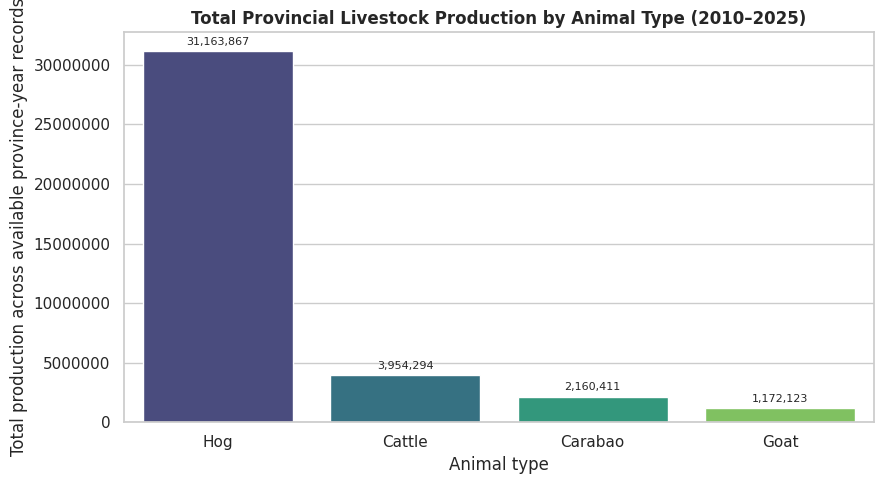

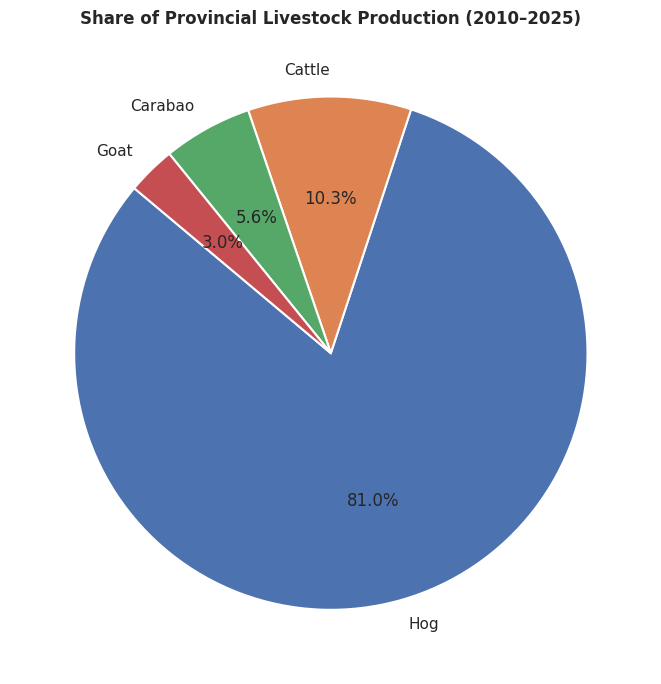

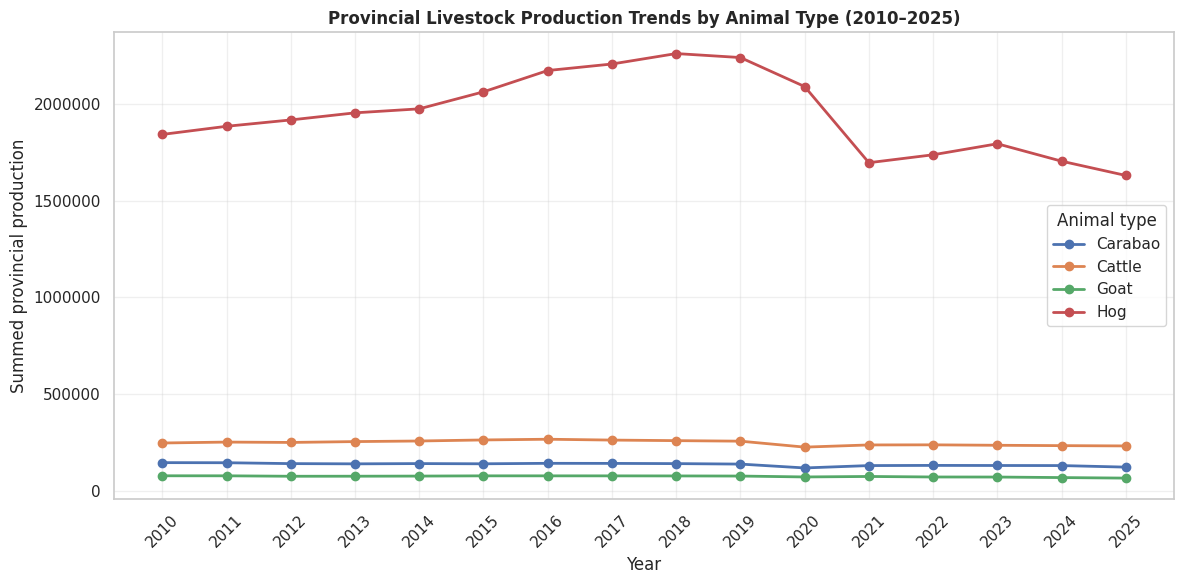

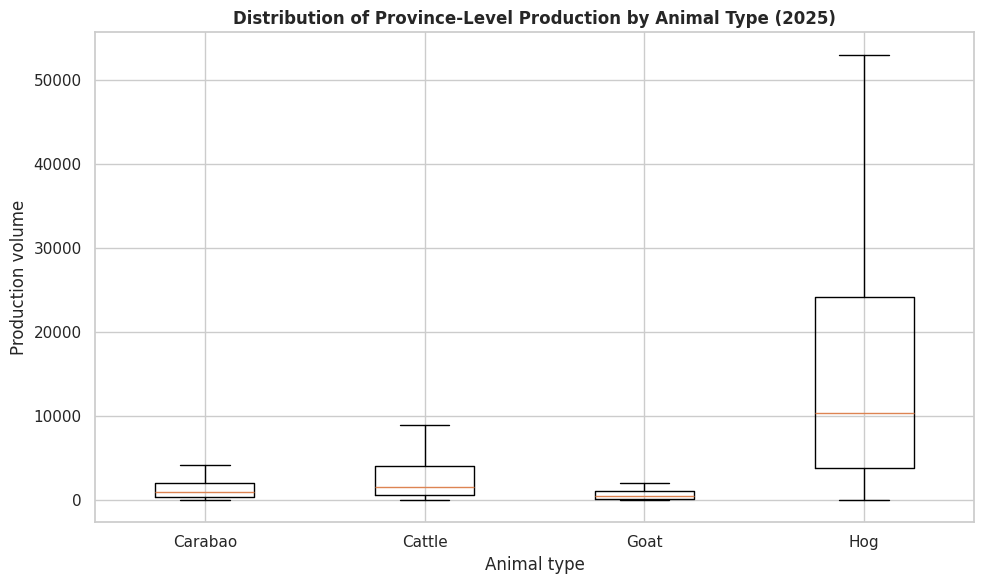

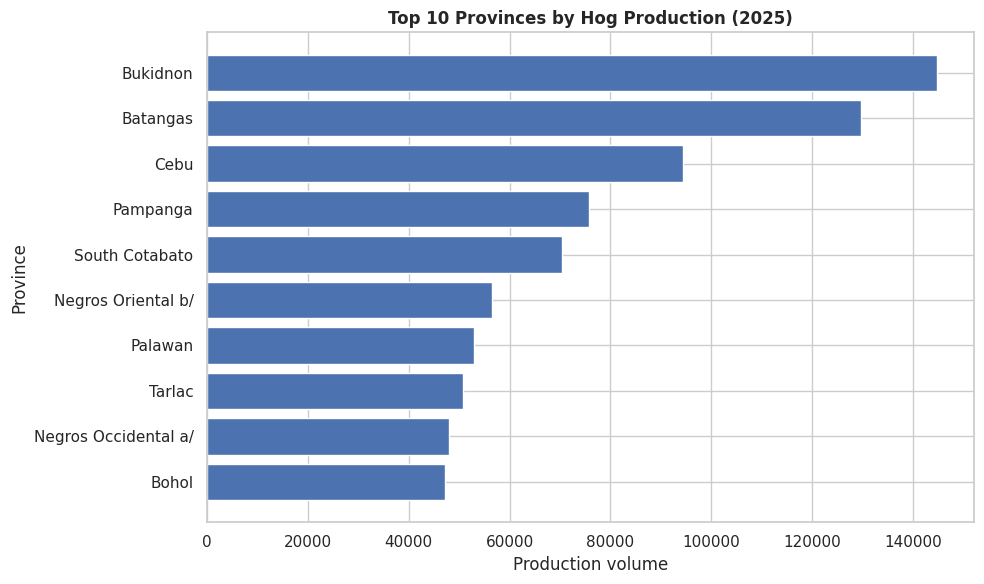

In [ ]:
# 3. DESCRIPTIVE ANALYTICS AND DATA VISUALIZATION

# Table: descriptive statistics for provincial annual production, by animal type.
descriptive_summary = (
    province_long.groupby('Animal Type')['Production']
    .agg(Count='count', Mean='mean', Median='median', Std_Dev='std', Minimum='min', Maximum='max')
    .reset_index()
    .sort_values('Mean', ascending=False)
)
print('=== DESCRIPTIVE STATISTICS BY ANIMAL TYPE ===')
display(descriptive_summary.style.format({
    'Mean': '{:,.2f}', 'Median': '{:,.2f}', 'Std_Dev': '{:,.2f}',
    'Minimum': '{:,.2f}', 'Maximum': '{:,.2f}'
}).background_gradient(cmap='Blues', subset=['Mean', 'Median']))
descriptive_summary.to_csv(os.path.join(OUTPUT_DIR, 'descriptive_summary_by_animal.csv'), index=False)

# Aggregate province-level production to compare animal types over the whole period.
total_by_animal = (
    province_long.groupby('Animal Type', as_index=False)['Production'].sum()
    .rename(columns={'Production': 'Total_Production_2010_2025'})
    .sort_values('Total_Production_2010_2025', ascending=False)
)
total_all = total_by_animal['Total_Production_2010_2025'].sum()
total_by_animal['Percentage Share (%)'] = total_by_animal['Total_Production_2010_2025'] / total_all * 100
print('\n=== TOTAL PROVINCIAL PRODUCTION AND SHARE (2010–2025) ===')
display(total_by_animal.style.format({
    'Total_Production_2010_2025': '{:,.2f}',
    'Percentage Share (%)': '{:.2f}%'
}).background_gradient(cmap='Greens', subset=['Percentage Share (%)']))
total_by_animal.to_csv(os.path.join(OUTPUT_DIR, 'total_production_share_by_animal.csv'), index=False)

# Chart 1: total production by animal type.
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=total_by_animal, x='Animal Type', y='Total_Production_2010_2025', hue='Animal Type', palette='viridis', legend=False)
plt.title('Total Provincial Livestock Production by Animal Type (2010–2025)', fontweight='bold')
plt.xlabel('Animal type')
plt.ylabel('Total production across available province-year records')
plt.ticklabel_format(style='plain', axis='y')
for bar in ax.patches:
    ax.annotate(f'{bar.get_height():,.0f}', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '01_total_production_by_animal_bar.png'), dpi=180, bbox_inches='tight')
plt.show()

# Chart 2: percentage share of each animal type.
plt.figure(figsize=(7, 7))
plt.pie(total_by_animal['Total_Production_2010_2025'], labels=total_by_animal['Animal Type'],
        autopct='%1.1f%%', startangle=140, wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
plt.title('Share of Provincial Livestock Production (2010–2025)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '02_production_share_pie.png'), dpi=180, bbox_inches='tight')
plt.show()

# Chart 3: annual trends by animal type using only province-level rows (avoids double counting totals).
annual_by_animal = province_long.groupby(['Year', 'Animal Type'], as_index=False)['Production'].sum()
plt.figure(figsize=(12, 6))
for animal, part in annual_by_animal.groupby('Animal Type'):
    part = part.sort_values('Year')
    plt.plot(part['Year'], part['Production'], marker='o', linewidth=2, label=animal)
plt.title('Provincial Livestock Production Trends by Animal Type (2010–2025)', fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Summed provincial production')
plt.xticks(YEARS, rotation=45)
plt.ticklabel_format(style='plain', axis='y')
plt.legend(title='Animal type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '03_production_trends_by_animal.png'), dpi=180, bbox_inches='tight')
plt.show()
annual_by_animal.to_csv(os.path.join(OUTPUT_DIR, 'annual_production_by_animal.csv'), index=False)

# Chart 4: boxplot showing distribution of province-level production in 2025.
province_2025 = province_long[province_long['Year'].eq(2025)].copy()
if not province_2025.empty:
    plt.figure(figsize=(10, 6))
    plot_data = [province_2025.loc[province_2025['Animal Type'].eq(a), 'Production'].dropna().values
                 for a in ['Carabao', 'Cattle', 'Goat', 'Hog']]
    plt.boxplot(plot_data, labels=['Carabao', 'Cattle', 'Goat', 'Hog'], showfliers=False)
    plt.title('Distribution of Province-Level Production by Animal Type (2025)', fontweight='bold')
    plt.xlabel('Animal type')
    plt.ylabel('Production volume')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, '04_provincial_distribution_2025_boxplot.png'), dpi=180, bbox_inches='tight')
    plt.show()

    # Chart 5: top 10 provinces by hog production in 2025.
    top_hog = province_2025[province_2025['Animal Type'].eq('Hog')].nlargest(10, 'Production').sort_values('Production')
    if not top_hog.empty:
        plt.figure(figsize=(10, 6))
        plt.barh(top_hog['Geolocation'], top_hog['Production'])
        plt.title('Top 10 Provinces by Hog Production (2025)', fontweight='bold')
        plt.xlabel('Production volume')
        plt.ylabel('Province')
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, '05_top_10_hog_producers_2025.png'), dpi=180, bbox_inches='tight')
        plt.show()
        top_hog.to_csv(os.path.join(OUTPUT_DIR, 'top_10_hog_producers_2025.csv'), index=False)

province_long.to_csv(os.path.join(OUTPUT_DIR, 'cleaned_provincial_long.csv'), index=False)

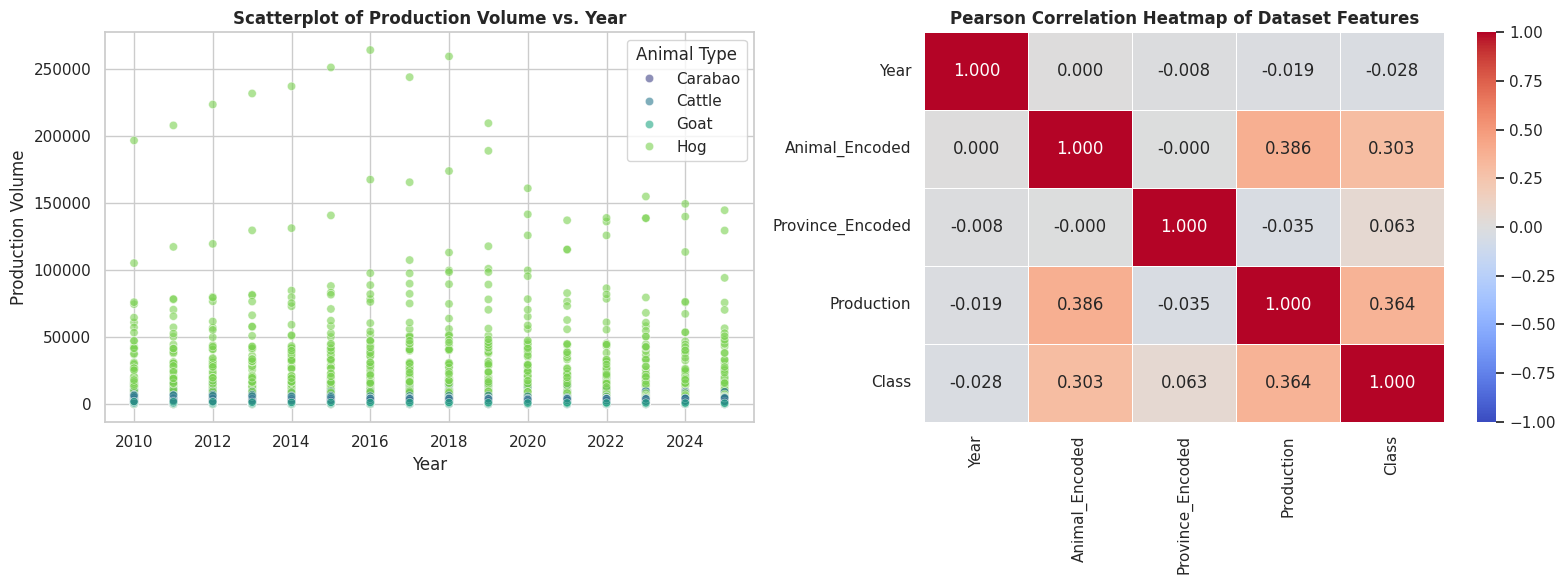

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Define model_df and encode features locally to support the correlation heatmap
median_val = province_long['Production'].median()
model_df = province_long.copy()
model_df['Class'] = (model_df['Production'] >= median_val).astype(int)

le_animal = LabelEncoder()
le_province = LabelEncoder()
model_df['Animal_Encoded'] = le_animal.fit_transform(model_df['Animal Type'])
model_df['Province_Encoded'] = le_province.fit_transform(model_df['Geolocation'])

# Calculate correlation matrix on numeric features
corr_df = model_df[['Year', 'Animal_Encoded', 'Province_Encoded', 'Production', 'Class']].corr(method='pearson')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Scatterplot: Production vs Year by Animal Type
sns.scatterplot(
    data=province_long,
    x='Year',
    y='Production',
    hue='Animal Type',
    alpha=0.6,
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Scatterplot of Production Volume vs. Year', fontweight='bold')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Production Volume')
axes[0].ticklabel_format(style='plain', axis='y')

# 2. Correlation Heatmap
sns.heatmap(
    corr_df,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=axes[1]
)
axes[1].set_title('Pearson Correlation Heatmap of Dataset Features', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '10_scatterplot_and_correlation_heatmap.png'), dpi=180, bbox_inches='tight')
plt.show()

Median production threshold: 1,648.4205
Class definition: 0 = Low Production; 1 = High Production (at or above the median).

=== CLASS DISTRIBUTION TABLE ===


,Production Class,Count,Share (%)
0,Low Production,2570,50.00%
1,High Production,2570,50.00%


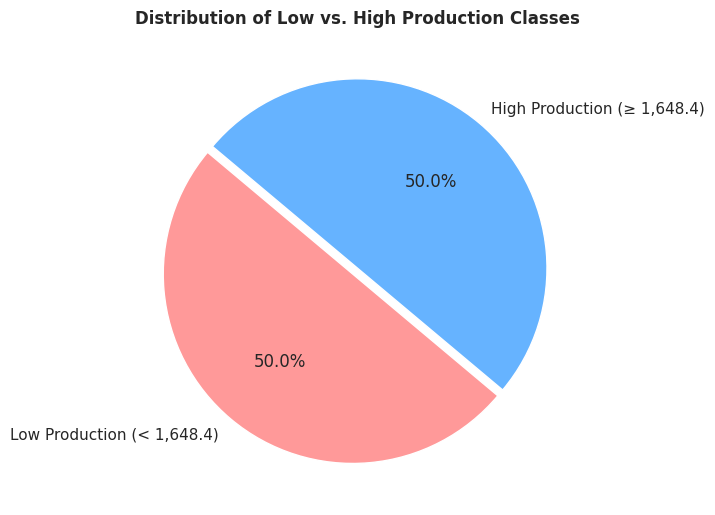

Original valid provincial records: 5,140
Training records before augmentation: 3,289
Validation records: 823 | Untouched final test records: 1,028

===== Logistic Regression =====
Validation accuracy before augmentation: 56.99%
Validation accuracy after augmentation:  57.35%
Synthetic training records created: 823
Final decision: Augmented model selected: validation accuracy improved.
Test accuracy: 54.28%
                 precision    recall  f1-score   support

 Low Production       0.54      0.54      0.54       514
High Production       0.54      0.55      0.55       514

       accuracy                           0.54      1028
      macro avg       0.54      0.54      0.54      1028
   weighted avg       0.54      0.54      0.54      1028


===== Decision Tree =====
Validation accuracy before augmentation: 78.61%
Validation accuracy after augmentation:  78.61%
Synthetic training records created: 823
Final decision: Augmentation tested; baseline retained because validation accuracy

,Model,Validation Accuracy Before,80% Threshold,Augmentation Triggered,Training Rows Before,Training Rows After Attempt,Synthetic Rows Created,Validation Accuracy After,Augmented Model Selected,Final Training Rows Used,Decision
0,Logistic Regression,56.99%,80%,Yes,3289,4112,823,57.35%,Yes,4112,Augmented model selected: validation accuracy improved.
1,Decision Tree,78.61%,80%,Yes,3289,4112,823,78.61%,No,3289,Augmentation tested; baseline retained because validation accuracy did not improve.
2,Random Forest,80.07%,80%,No,3289,3289,0,N/A,No,3289,Not needed: validation accuracy is at least 80%.
3,Gradient Boosting,94.53%,80%,No,3289,3289,0,N/A,No,3289,Not needed: validation accuracy is at least 80%.


Original model dataset records: 5,140
Original training records per model: 3,289
Note: synthetic rows are training-only generated records, not new official livestock measurements.


In [ ]:
# 4. CLASSIFICATION MODELING WITH CONDITIONAL RECORD AUGMENTATION

# Follow the example notebook's approach: classify observations as High/Low based on
# the median provincial production. Split into training, validation, and test sets.
# The validation set triggers augmentation. The test set is kept untouched for final scoring.
median_val = province_long['Production'].median()
model_df = province_long.copy()
model_df['Class'] = (model_df['Production'] >= median_val).astype(int)  # 0 = Low, 1 = High

print(f'Median production threshold: {median_val:,.4f}')
print('Class definition: 0 = Low Production; 1 = High Production (at or above the median).')
class_counts = model_df['Class'].value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    'Production Class': ['Low Production', 'High Production'],
    'Count': [int(class_counts.loc[0]), int(class_counts.loc[1])],
    'Share (%)': [class_counts.loc[0] / len(model_df) * 100, class_counts.loc[1] / len(model_df) * 100]
})
print('\n=== CLASS DISTRIBUTION TABLE ===')
display(class_summary.style.format({'Share (%)': '{:.2f}%'}))
class_summary.to_csv(os.path.join(OUTPUT_DIR, 'production_class_distribution.csv'), index=False)

plt.figure(figsize=(7, 7))
plt.pie(class_counts.values,
        labels=[f'Low Production (< {median_val:,.1f})', f'High Production (≥ {median_val:,.1f})'],
        autopct='%1.1f%%', startangle=140, colors=['#ff9999', '#66b3ff'], explode=(0.04, 0))
plt.title('Distribution of Low vs. High Production Classes', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '06_production_class_distribution_pie.png'), dpi=180, bbox_inches='tight')
plt.show()

# Encode categorical features, matching the old notebook's structure.
le_animal = LabelEncoder()
le_province = LabelEncoder()
model_df['Animal_Encoded'] = le_animal.fit_transform(model_df['Animal Type'])
model_df['Province_Encoded'] = le_province.fit_transform(model_df['Geolocation'])

FEATURES = ['Year', 'Animal_Encoded', 'Province_Encoded']
TARGET = 'Class'
X = model_df[FEATURES].copy()
y = model_df[TARGET].copy()

# Hold out 20% for final testing. The remaining 80% is split into training and validation.
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_development, y_development, test_size=0.20, random_state=RANDOM_STATE, stratify=y_development
)
print(f'Original valid provincial records: {len(model_df):,}')
print(f'Training records before augmentation: {len(X_train):,}')
print(f'Validation records: {len(X_val):,} | Untouched final test records: {len(X_test):,}')

# SMOTENC treats Animal and Province as categories, not continuous numeric values.
# Year remains numeric. Synthetic rows are generated from X_train/y_train only.
model_specs = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE)
}

fitted_models = {}
metrics_summary = []
augmentation_rows = []
test_predictions = model_df.loc[X_test.index, ['Year', 'Animal Type', 'Geolocation', 'Production', 'Class']].copy()
probability_by_model = {}

for model_name, model_spec in model_specs.items():
    # Step 1: baseline model trained on the real training records only.
    baseline_model = clone(model_spec)
    baseline_model.fit(X_train, y_train)
    validation_pred_before = baseline_model.predict(X_val)
    validation_acc_before = accuracy_score(y_val, validation_pred_before)

    selected_model = baseline_model
    selected_training_rows = len(X_train)
    attempted_augmented_rows = len(X_train)
    synthetic_rows_created = 0
    validation_acc_after = np.nan
    augmentation_triggered = validation_acc_before < ACCURACY_THRESHOLD
    augmentation_selected = False
    decision_text = 'Not needed: validation accuracy is at least 80%.'

    # Step 2: only if validation accuracy is below 80%, make extra synthetic training rows.
    if augmentation_triggered:
        counts = y_train.value_counts()
        if counts.min() > 1:
            sampling_strategy = {
                int(class_label): int(np.ceil(count * AUGMENT_FACTOR))
                for class_label, count in counts.items()
            }
            sampler = SMOTENC(
                categorical_features=[1, 2],  # Animal_Encoded and Province_Encoded
                sampling_strategy=sampling_strategy,
                random_state=RANDOM_STATE,
                k_neighbors=min(5, int(counts.min()) - 1)
            )
            X_augmented, y_augmented = sampler.fit_resample(X_train, y_train)
            attempted_augmented_rows = len(X_augmented)
            synthetic_rows_created = len(X_augmented) - len(X_train)

            augmented_model = clone(model_spec)
            augmented_model.fit(X_augmented, y_augmented)
            validation_pred_after = augmented_model.predict(X_val)
            validation_acc_after = accuracy_score(y_val, validation_pred_after)

            # Keep augmentation only if it improves validation accuracy. This prevents
            # adding synthetic rows just for a larger count when performance gets worse.
            if validation_acc_after > validation_acc_before:
                selected_model = augmented_model
                selected_training_rows = len(X_augmented)
                augmentation_selected = True
                decision_text = 'Augmented model selected: validation accuracy improved.'
            else:
                decision_text = 'Augmentation tested; baseline retained because validation accuracy did not improve.'
        else:
            decision_text = 'Accuracy below 80%, but too few samples to safely generate synthetic rows.'

    # Step 3: evaluate the selected model once on the untouched test set.
    y_pred = selected_model.predict(X_test)
    y_prob = selected_model.predict_proba(X_test)[:, 1]
    fitted_models[model_name] = selected_model
    probability_by_model[model_name] = y_prob

    auc = roc_auc_score(y_test, y_prob) if y_test.nunique() == 2 else np.nan
    metrics_summary.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': auc,
        'Validation Accuracy Before Augmentation': validation_acc_before,
        'Validation Accuracy After Augmentation': validation_acc_after,
        'Augmentation Triggered': 'Yes' if augmentation_triggered else 'No',
        'Synthetic Records Created': synthetic_rows_created,
        'Training Records Used': selected_training_rows,
        'Augmentation Decision': decision_text
    })
    test_predictions[f'{model_name} - Predicted Class'] = y_pred
    test_predictions[f'{model_name} - Probability High'] = y_prob

    augmentation_rows.append({
        'Model': model_name,
        'Validation Accuracy Before': validation_acc_before,
        '80% Threshold': ACCURACY_THRESHOLD,
        'Augmentation Triggered': 'Yes' if augmentation_triggered else 'No',
        'Training Rows Before': len(X_train),
        'Training Rows After Attempt': attempted_augmented_rows,
        'Synthetic Rows Created': synthetic_rows_created,
        'Validation Accuracy After': validation_acc_after,
        'Augmented Model Selected': 'Yes' if augmentation_selected else 'No',
        'Final Training Rows Used': selected_training_rows,
        'Decision': decision_text
    })

    print(f'\n===== {model_name} =====')
    print(f'Validation accuracy before augmentation: {validation_acc_before:.2%}')
    if augmentation_triggered:
        if not pd.isna(validation_acc_after):
            print(f'Validation accuracy after augmentation:  {validation_acc_after:.2%}')
        print(f'Synthetic training records created: {synthetic_rows_created:,}')
        print(f'Final decision: {decision_text}')
    print(f'Test accuracy: {accuracy_score(y_test, y_pred):.2%}')
    print(classification_report(y_test, y_pred, labels=[0, 1], target_names=['Low Production', 'High Production'], zero_division=0))

comparison_df = pd.DataFrame(metrics_summary).sort_values(
    by=['Accuracy', 'ROC-AUC', 'F1-Score'], ascending=False
).reset_index(drop=True)
augmentation_df = pd.DataFrame(augmentation_rows)

print('\n=== CONDITIONAL AUGMENTATION / RECORD COUNT LOG ===')
display(augmentation_df.style.format({
    'Validation Accuracy Before': '{:.2%}',
    '80% Threshold': '{:.0%}',
    'Validation Accuracy After': lambda x: 'N/A' if pd.isna(x) else f'{x:.2%}'
}).set_properties(**{'text-align': 'center'}))

augmentation_df.to_csv(os.path.join(OUTPUT_DIR, 'conditional_augmentation_record_log.csv'), index=False)
test_predictions.to_csv(os.path.join(OUTPUT_DIR, 'test_predictions_all_models.csv'), index=False)
print(f'Original model dataset records: {len(model_df):,}')
print(f'Original training records per model: {len(X_train):,}')
print('Note: synthetic rows are training-only generated records, not new official livestock measurements.')

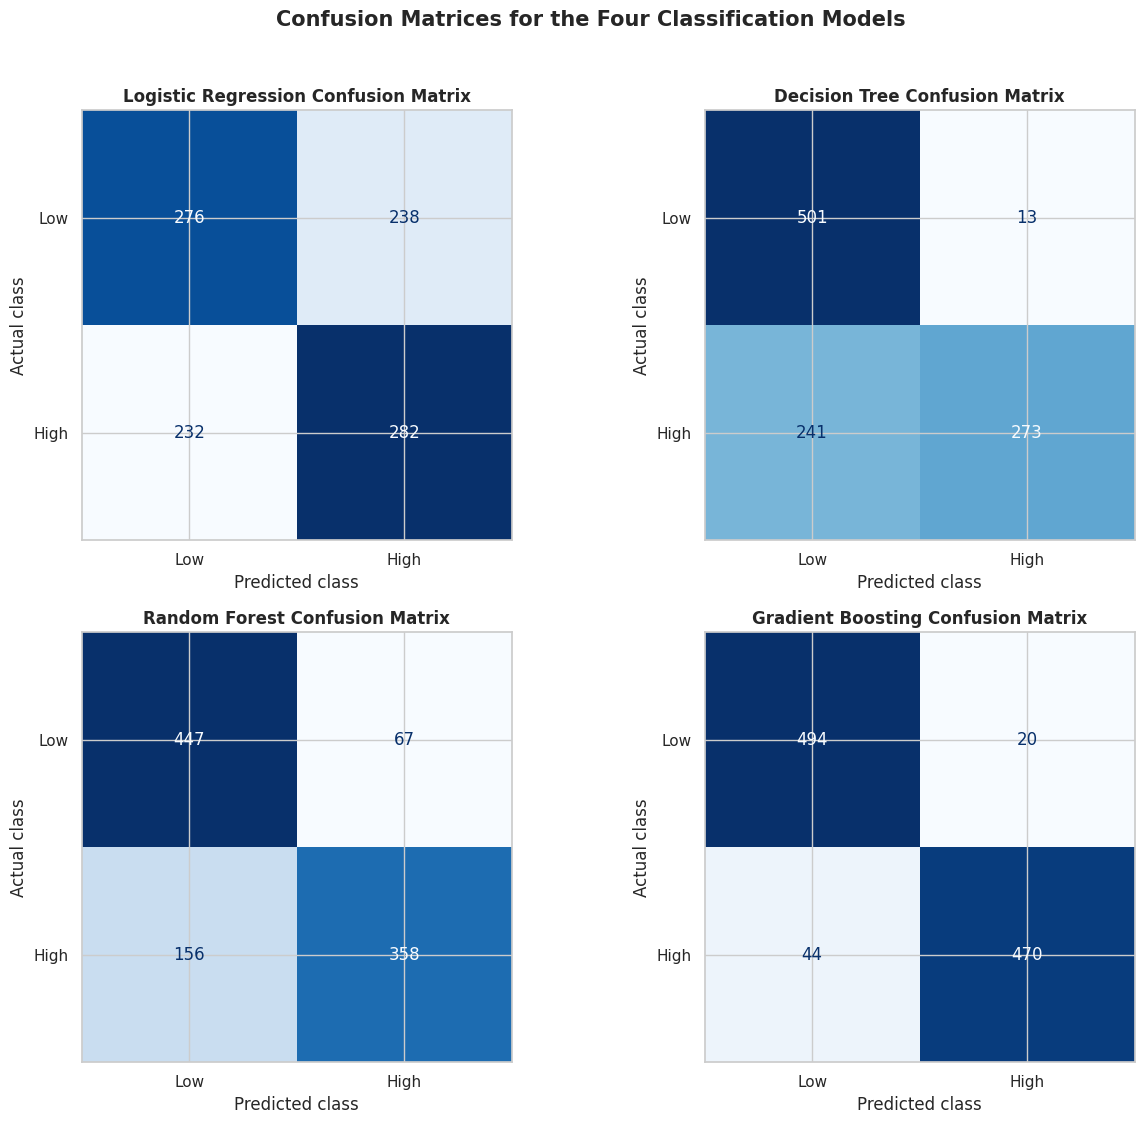

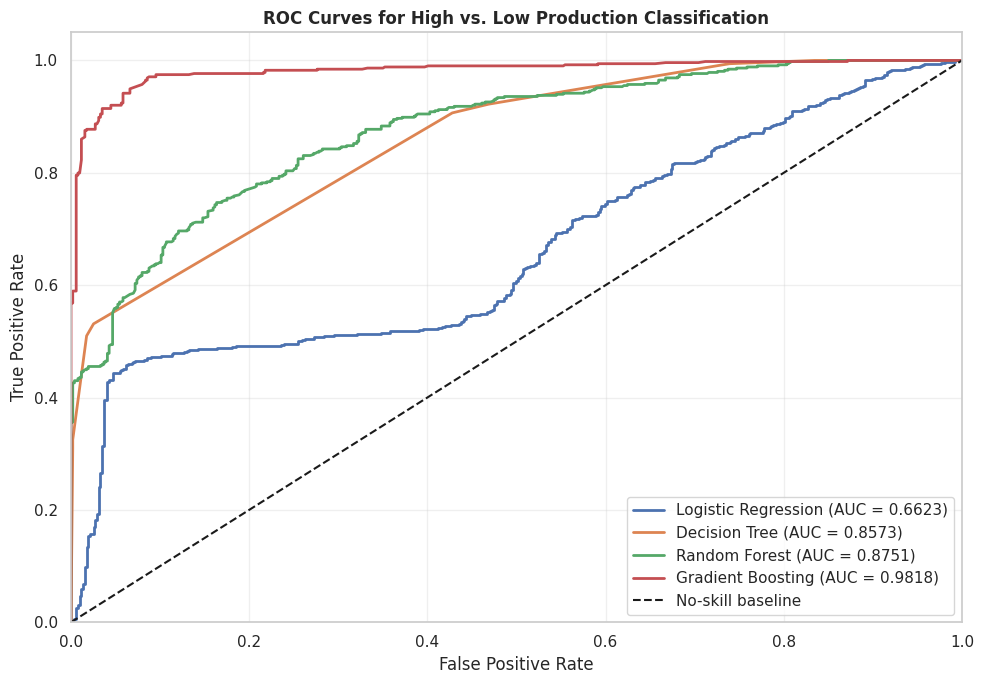

ROC-AUC interpretation: 0.50 is near chance-level ranking; values closer to 1.00 indicate better separation between the two classes.


In [ ]:
# 5. CONFUSION MATRICES AND ROC CURVES

# Confusion Matrix: compare the actual and predicted classes for all four models.
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()
for ax, (model_name, model) in zip(axes, fitted_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low', 'High'])
    disp.plot(ax=ax, colorbar=False, values_format='d', cmap='Blues')
    ax.set_title(f'{model_name} Confusion Matrix', fontweight='bold')
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
plt.suptitle('Confusion Matrices for the Four Classification Models', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '07_confusion_matrices_all_models.png'), dpi=180, bbox_inches='tight')
plt.show()

# ROC curve: true-positive rate versus false-positive rate across thresholds.
plt.figure(figsize=(10, 7))
for model_name, y_prob in probability_by_model.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f'{model_name} (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='No-skill baseline')
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for High vs. Low Production Classification', fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '08_roc_curves_all_models.png'), dpi=180, bbox_inches='tight')
plt.show()

print('ROC-AUC interpretation: 0.50 is near chance-level ranking; values closer to 1.00 indicate better separation between the two classes.')

## 6. Performance Comparison Table

This table is computed from final predictions on the untouched test set. Models with validation accuracy below 80% first attempt to increase the training-record count by 25% per class using SMOTENC. The augmented model is retained only if its validation accuracy improves. The table also records whether augmentation was triggered and how many synthetic records were generated. Synthetic records are not official livestock measurements.

=== TABLE OF COMPARISON FOR MODEL RESULTS ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,93.77%,95.92%,91.44%,93.63%,0.9818
1,Random Forest,78.31%,84.24%,69.65%,76.25%,0.8751
2,Decision Tree,75.29%,95.45%,53.11%,68.25%,0.8573
3,Logistic Regression,54.28%,54.23%,54.86%,54.55%,0.6623



Plain-text version of comparison table:
              Model Accuracy Precision Recall F1-Score ROC-AUC
  Gradient Boosting   93.77%    95.92% 91.44%   93.63%  0.9818
      Random Forest   78.31%    84.24% 69.65%   76.25%  0.8751
      Decision Tree   75.29%    95.45% 53.11%   68.25%  0.8573
Logistic Regression   54.28%    54.23% 54.86%   54.55%  0.6623

=== RECORD INCREASE SUMMARY (IF VALIDATION ACCURACY < 80%) ===


,Model,Validation Accuracy Before,Augmentation Triggered,Training Rows Before,Training Rows After Attempt,Synthetic Rows Created,Validation Accuracy After,Augmented Model Selected,Final Training Rows Used
0,Logistic Regression,56.99%,Yes,3289,4112,823,57.35%,Yes,4112
1,Decision Tree,78.61%,Yes,3289,4112,823,78.61%,No,3289
2,Random Forest,80.07%,No,3289,3289,0,N/A,No,3289
3,Gradient Boosting,94.53%,No,3289,3289,0,N/A,No,3289


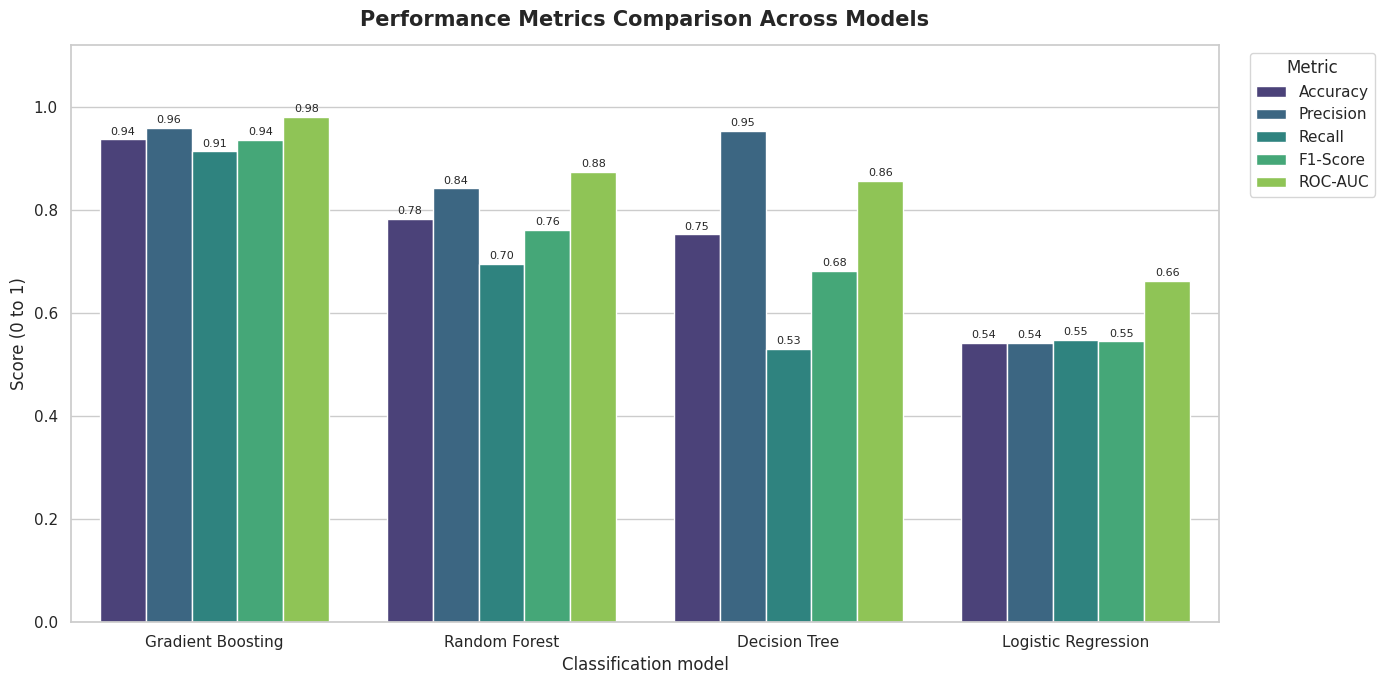

Highest Accuracy model on this test split: Gradient Boosting (Accuracy = 93.77%)


In [ ]:
# 6. PERFORMANCE COMPARISON TABLE (LIVE RESULTS)

score_columns = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
comparison_table = comparison_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].copy()

print('=== TABLE OF COMPARISON FOR MODEL RESULTS ===')
display(
    comparison_table.style
    .format({
        'Accuracy': '{:.2%}',
        'Precision': '{:.2%}',
        'Recall': '{:.2%}',
        'F1-Score': '{:.2%}',
        'ROC-AUC': '{:.4f}'
    })
    .background_gradient(cmap='Greens', subset=score_columns)
    .set_properties(**{'text-align': 'center'})
    .set_caption('Model Performance Comparison on the Untouched Test Dataset')
)

print('\nPlain-text version of comparison table:')
print(comparison_table.to_string(index=False, formatters={
    'Accuracy': lambda x: f'{x:.2%}',
    'Precision': lambda x: f'{x:.2%}',
    'Recall': lambda x: f'{x:.2%}',
    'F1-Score': lambda x: f'{x:.2%}',
    'ROC-AUC': lambda x: f'{x:.4f}'
}))

# Save the main comparison table and a second table with the record-augmentation audit details.
comparison_df.to_csv(os.path.join(OUTPUT_DIR, 'model_comparison.csv'), index=False)
comparison_table.to_csv(os.path.join(OUTPUT_DIR, 'model_comparison_compact.csv'), index=False)
print('\n=== RECORD INCREASE SUMMARY (IF VALIDATION ACCURACY < 80%) ===')
display(augmentation_df[['Model', 'Validation Accuracy Before', 'Augmentation Triggered',
                          'Training Rows Before', 'Training Rows After Attempt',
                          'Synthetic Rows Created', 'Validation Accuracy After',
                          'Augmented Model Selected', 'Final Training Rows Used']].style.format({
    'Validation Accuracy Before': '{:.2%}',
    'Validation Accuracy After': lambda x: 'N/A' if pd.isna(x) else f'{x:.2%}'
}))

# Comparison chart follows the style of the example notebook.
comparison_long = comparison_table.melt(
    id_vars='Model', value_vars=score_columns, var_name='Metric', value_name='Score'
)
plt.figure(figsize=(14, 7))
ax = sns.barplot(data=comparison_long, x='Model', y='Score', hue='Metric', palette='viridis')
plt.title('Performance Metrics Comparison Across Models', fontsize=15, fontweight='bold', pad=14)
plt.xlabel('Classification model')
plt.ylabel('Score (0 to 1)')
plt.ylim(0, 1.12)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=8, padding=2)
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '09_model_comparison_chart.png'), dpi=180, bbox_inches='tight')
plt.show()

best_model_name = comparison_df.iloc[0]['Model']
print(f'Highest Accuracy model on this test split: {best_model_name} (Accuracy = {comparison_df.iloc[0]["Accuracy"]:.2%})')

In [ ]:
# 7. PREDICT THE 2026 HIGH/LOW PRODUCTION CATEGORY

# Retrain each algorithm on all available real provincial observations, then classify the
# 2026 category for provinces with a valid 2025 observation. Synthetic training records are
# not used in this final refit, so future predictions use the original observations only.
latest_2025 = province_long[province_long['Year'].eq(2025)].dropna(subset=['Production']).copy()
latest_2025['Animal_Encoded'] = le_animal.transform(latest_2025['Animal Type'])
latest_2025['Province_Encoded'] = le_province.transform(latest_2025['Geolocation'])
X_all = model_df[FEATURES]
y_all = model_df[TARGET]

X_future = latest_2025[FEATURES].copy()
X_future['Year'] = 2026

future_results = latest_2025[['Geolocation', 'Animal Type', 'Year', 'Production']].rename(
    columns={'Year': 'Current Year', 'Production': 'Production in 2025'}
).copy()
final_models = {}
for model_name, model_spec in model_specs.items():
    final_model = clone(model_spec)
    final_model.fit(X_all, y_all)
    final_models[model_name] = final_model
    pred = final_model.predict(X_future)
    prob = final_model.predict_proba(X_future)[:, 1]
    future_results[f'{model_name} - Predicted 2026 Class'] = np.where(pred == 1, 'High Production', 'Low Production')
    future_results[f'{model_name} - Probability High'] = prob

future_results.to_csv(os.path.join(OUTPUT_DIR, 'predicted_2026_high_low_by_province_animal.csv'), index=False)
print('Example 2026 High/Low category predictions:')
display(future_results.head(12).round(4))

# Helper function similar to the older notebook's example prediction function.
def predict_production_class(year, animal_type, province_name):
    """Predict High or Low production category for a year, animal type, and province."""
    try:
        animal_enc = le_animal.transform([animal_type])[0]
        province_name = str(province_name).strip().lstrip('.')
        province_enc = le_province.transform([province_name])[0]
        input_features = pd.DataFrame(
            [[year, animal_enc, province_enc]], columns=FEATURES
        )
        best_model = final_models[best_model_name]
        predicted_class = int(best_model.predict(input_features)[0])
        probability_high = float(best_model.predict_proba(input_features)[0][1])
        class_label = 'High Production' if predicted_class == 1 else 'Low Production'
        confidence = probability_high if predicted_class == 1 else 1 - probability_high
        print(f'Year: {year} | Animal: {animal_type} | Province: {province_name}')
        print(f'Predicted class: {class_label} | Model: {best_model_name} | Confidence: {confidence:.2%}')
        print('-' * 70)
    except ValueError as error:
        print('Could not make prediction. Check the animal type and province name.')
        print('Details:', error)

# Show three example predictions using provinces that exist in the dataset.
for row in latest_2025[['Geolocation', 'Animal Type']].drop_duplicates().head(3).itertuples(index=False, name=None):
    predict_production_class(2026, row[1], row[0])

summary_text = [
    'Livestock Production Classification Summary',
    f'Province-level annual observations used: {len(model_df)}',
    f'Original training rows before augmentation: {len(X_train)}',
    f'Total synthetic rows created across model augmentation attempts: {int(augmentation_df["Synthetic Rows Created"].sum())}',
    f'Median production threshold: {median_val:.4f}',
    'Target: 0 = Low Production; 1 = High Production (at or above the provincial-observation median).',
    f'Train rows before augmentation: {len(X_train)}; validation rows: {len(X_val)}; untouched test rows: {len(X_test)}.',
    f'Highest-accuracy model on the untouched test set: {best_model_name} ({comparison_df.iloc[0]["Accuracy"]:.4f} accuracy).' ,
    'Caution: 2026 predictions are High/Low category estimates, not predictions of exact production volume.',
    'If validation accuracy is below 80%, SMOTENC attempts to increase only training records; the augmented model is used only if validation accuracy improves. The test set is not used to trigger augmentation or choose between a model and its augmented version.' , 'The test-set comparison identifies the best-scoring model in this run, so treat that ranking as exploratory. The random split may be optimistic for predicting unseen future years because records from multiple years are mixed across train and test sets.',
    '', 'Model comparison:', comparison_df.to_string(index=False)
]
with open(os.path.join(OUTPUT_DIR, 'analysis_summary.txt'), 'w', encoding='utf-8') as f:
    f.write('\n'.join(summary_text))

Example 2026 High/Low category predictions:


,Geolocation,Animal Type,Current Year,Production in 2025,Logistic Regression - Predicted 2026 Class,Logistic Regression - Probability High,Decision Tree - Predicted 2026 Class,Decision Tree - Probability High,Random Forest - Predicted 2026 Class,Random Forest - Probability High,Gradient Boosting - Predicted 2026 Class,Gradient Boosting - Probability High
15,Abra,Carabao,2025,653.2300,Low Production,0.2308,Low Production,0.0000,Low Production,0.0879,Low Production,0.0277
31,Abra,Cattle,2025,1195.2500,Low Production,0.3477,Low Production,0.3564,Low Production,0.1998,Low Production,0.1619
47,Abra,Goat,2025,420.6970,Low Production,0.4864,Low Production,0.0000,Low Production,0.1009,Low Production,0.0394
63,Abra,Hog,2025,3373.7449,High Production,0.6272,High Production,0.9098,High Production,0.8985,High Production,0.9695
79,Agusan del Norte,Carabao,2025,570.6000,Low Production,0.2318,Low Production,0.0000,Low Production,0.0791,Low Production,0.0365
95,Agusan del Norte,Cattle,2025,295.3700,Low Production,0.3490,Low Production,0.3564,Low Production,0.1924,Low Production,0.1586
111,Agusan del Norte,Goat,2025,80.5771,Low Production,0.4878,Low Production,0.0000,Low Production,0.0907,Low Production,0.0293
127,Agusan del Norte,Hog,2025,6807.4462,High Production,0.6285,High Production,0.9098,High Production,0.9085,High Production,0.9817
143,Agusan del Sur,Carabao,2025,1056.7900,Low Production,0.2328,Low Production,0.0000,Low Production,0.0772,Low Production,0.0365
159,Agusan del Sur,Cattle,2025,307.7950,Low Production,0.3502,Low Production,0.3564,Low Production,0.1899,Low Production,0.1586


Year: 2026 | Animal: Carabao | Province: Abra
Predicted class: Low Production | Model: Gradient Boosting | Confidence: 97.23%
----------------------------------------------------------------------
Year: 2026 | Animal: Cattle | Province: Abra
Predicted class: Low Production | Model: Gradient Boosting | Confidence: 83.81%
----------------------------------------------------------------------
Year: 2026 | Animal: Goat | Province: Abra
Predicted class: Low Production | Model: Gradient Boosting | Confidence: 96.06%
----------------------------------------------------------------------
